# QumPy tutorial

The course TPs redone with QumPy. Every cell runs as is. Compare it with the
original notebooks to see how much shorter the code gets.

Useful at any time: `qp.cheatsheet()`, `Qum.settings()`, `help(qp.<function>)`.

In [1]:
import qumpy as qp
from qumpy import Qum

Qum.seed = 2026      # reproducible results
Qum.precision = 4
qp.versions()

Version information
----------------------------------
  qumpy               0.1.0
  qiskit              2.2.0
  qiskit_aer          0.17.2
  qiskit_ibm_runtime  0.41.1
  numpy               2.4.6
  scipy               1.17.1
  matplotlib          3.11.2
  python              3.11.16
  system              Darwin arm64


In [2]:
Qum.settings()

QumPy settings
------------------------------------------------------------------------
  Qum.shots         = 1024        # number of repetitions used by .run()
  Qum.precision     = 4           # decimals shown when printing states / matrices
  Qum.seed          = 2026        # random seed (None = different result each run)
  Qum.backend       = 'ideal'     # 'ideal' (perfect simulator) or 'noisy' (fake IBM device)
  Qum.device        = 'manila'    # fake device used when backend='noisy' ('manila', 'generic')
  Qum.draw          = 'mpl'       # default drawing style: 'mpl', 'text' or 'latex'
  Qum.auto_measure  = True        # measure all qubits automatically if .run() finds no measurement


## 1. Kets, bras and inner products (TP 1)

In [3]:
psi = qp.ket("+")
qp.show(psi)
qp.show(psi, style="ket")

<IPython.core.display.Latex object>

<IPython.core.display.Math object>

In [4]:
qp.show(qp.ket([1, 1, 0, 1]), prefix=r"|\psi\rangle = ")   # normalised automatically

<IPython.core.display.Latex object>

In [5]:
a, b = qp.ket("0"), qp.ket("+")
print("<a|b> =", qp.inner(a, b))
print("|a><a| =\n", qp.outer(a))
print("<b| =", qp.bra(b))

<a|b> = (0.7071067811865475+0j)
|a><a| =
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
<b| = [[0.7071-0.j 0.7071-0.j]]


## 2. Operators

In [6]:
qp.show(qp.H)
U = qp.random_unitary(1, seed=123456)
print("unitary?", qp.is_unitary(U), "  U†U = I ?", qp.equal(qp.dagger(U).compose(U), qp.I))
qp.show(qp.tensor(qp.X, qp.Z))

<IPython.core.display.Latex object>

unitary? True   U†U = I ? True


<IPython.core.display.Latex object>

In [7]:
qp.dirac(qp.apply(qp.X, "0"))

'|1⟩'

## 3. Single-qubit circuits (TP 2)

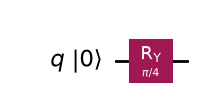

In [8]:
c = qp.Circuit(1).ry(qp.pi / 4, 0)
c.draw()

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

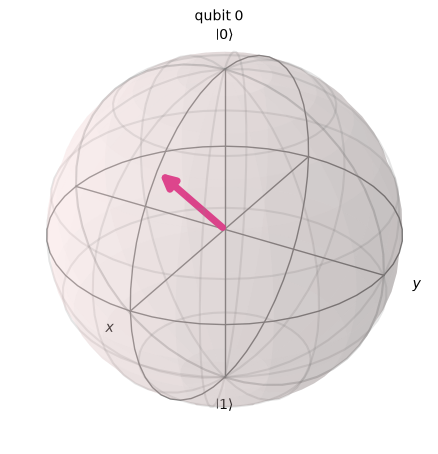

In [9]:
qp.show(c.state())
c.show_unitary()
c.bloch()

## 4. Two qubits, measurement and a noisy device (TP 3)

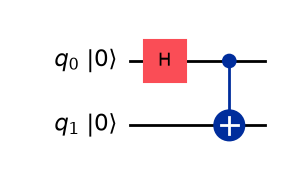

In [10]:
bell = qp.Circuit(2).h(0).cx(0, 1)
bell.draw()

In [11]:
print(qp.dirac(bell.state()))
rho = qp.density_matrix(bell)
rho_1 = qp.keep(rho, 1)
qp.show(rho_1)
print("purity of the pair:", qp.purity(rho), "  of one qubit:", qp.purity(rho_1))
print("entangled?", qp.is_entangled(bell.state()))

0.7071|00⟩ + 0.7071|11⟩


<IPython.core.display.Latex object>

purity of the pair: 1.0   of one qubit: 0.5
entangled? True


Counts({'00': 5083, '11': 4917}, shots=10000)
Counts({'00': 4882, '01': 211, '10': 157, '11': 4750}, shots=10000)


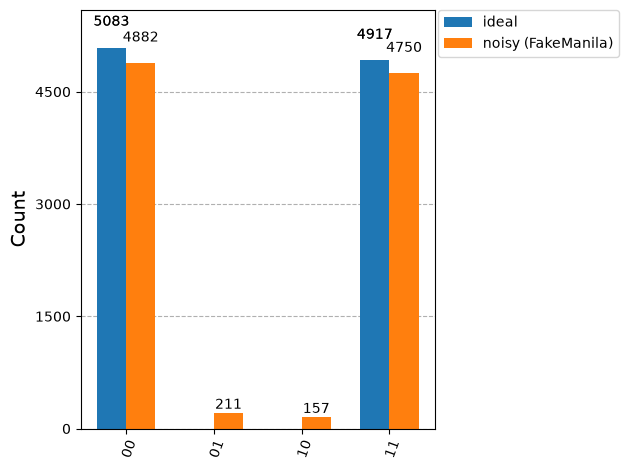

In [12]:
Qum.shots = 10000
bell.measure()
ideal = bell.run()
noisy = bell.run(backend="noisy")
print(ideal)
print(noisy)
qp.histogram(ideal, noisy, legend=["ideal", "noisy (FakeManila)"])

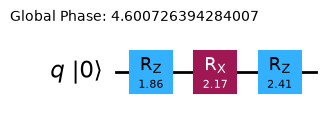

In [13]:
# rewrite a random gate using only rx, rz and cx
c = qp.Circuit(1).gate(qp.random_unitary(1), 0, label="U")
c.compile(basis=["rx", "rz", "cx"]).draw()

## 5. Teleportation (TP 4), step by step with named registers

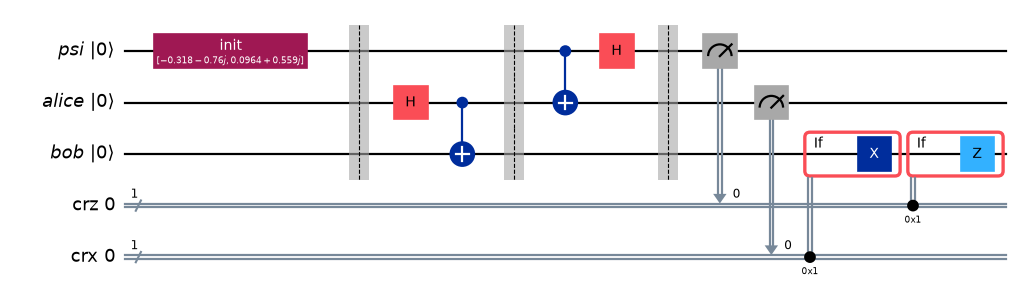

In [14]:
psi = qp.random_state(1)
c = qp.Circuit(psi=1, alice=1, bob=1, bits={"crz": 1, "crx": 1})
c.init(psi, "psi").barrier()
c.h("alice").cx("alice", "bob").barrier()
c.cx("psi", "alice").h("psi").barrier()
c.measure("psi", "crz").measure("alice", "crx")
with c.if_bit("crx", 1):
    c.x("bob")
with c.if_bit("crz", 1):
    c.z("bob")
c.draw(scale=0.8)

fidelity(Bob, psi) = 0.9999999999999999


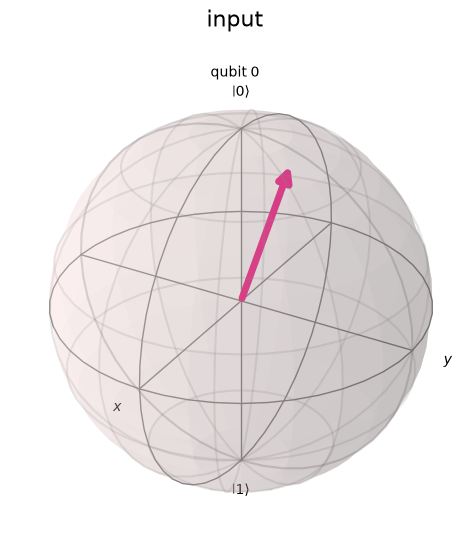

In [15]:
bob = qp.keep(c.state(), 2)          # qubit 2 = bob
print("fidelity(Bob, psi) =", qp.fidelity(bob, psi))
qp.bloch(psi, title="input")

In [16]:
# the same thing, ready-made
qp.fidelity(qp.keep(qp.teleportation(psi).state(), 2), psi)

0.9999999999999999

## 6. Deutsch–Jozsa and Bernstein–Vazirani (TP 5)

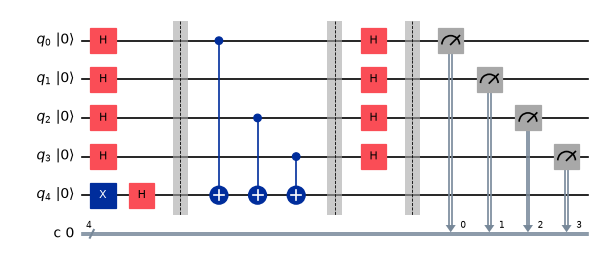

In [17]:
dj = qp.deutsch_jozsa(4, kind="balanced")
dj.draw(scale=0.6)

In [18]:
for kind in ["constant", "balanced"]:
    counts = qp.deutsch_jozsa(4, kind=kind).run(shots=1)
    print(f"{kind:>9} oracle ->", counts, "->", qp.dj_answer(counts))

 constant oracle -> Counts({'0000': 1}, shots=1) -> constant
 balanced oracle -> Counts({'1101': 1}, shots=1) -> balanced


In [19]:
qp.bernstein_vazirani("1011").run(shots=100)

Counts({'1011': 100}, shots=100)

## 7. Quantum Fourier Transform

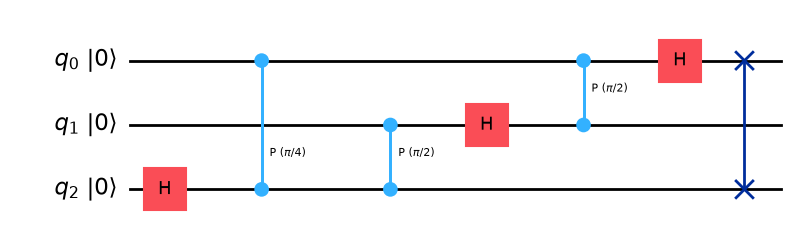

In [20]:
qft = qp.qft(3)
qft.draw()

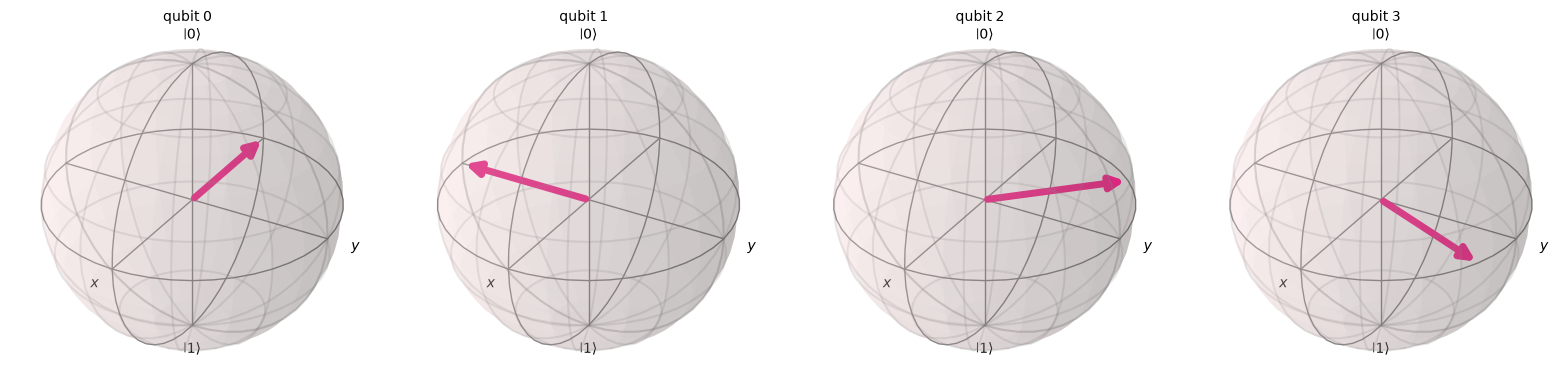

In [21]:
c = qp.Circuit(4).x(0).x(1)
c.add(qp.qft(4))
qp.bloch(c)

## 8. Grover search

iterations: 2


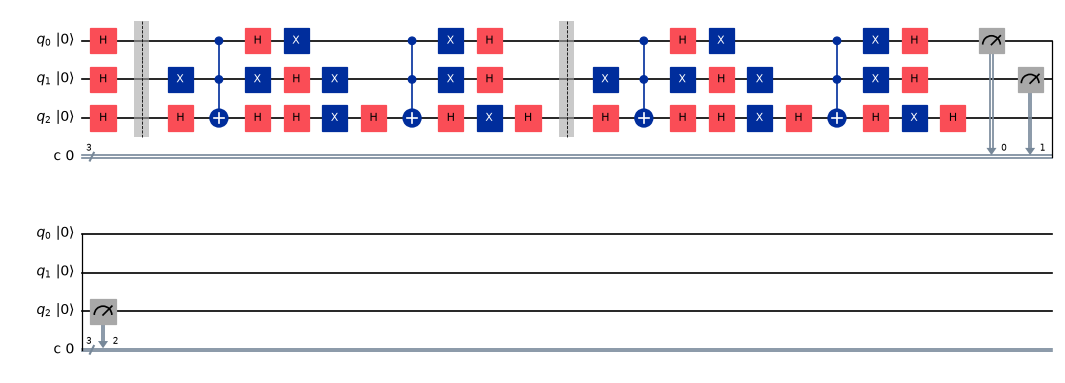

In [22]:
g = qp.grover("101")
print("iterations:", g.iterations)
g.draw(scale=0.6)

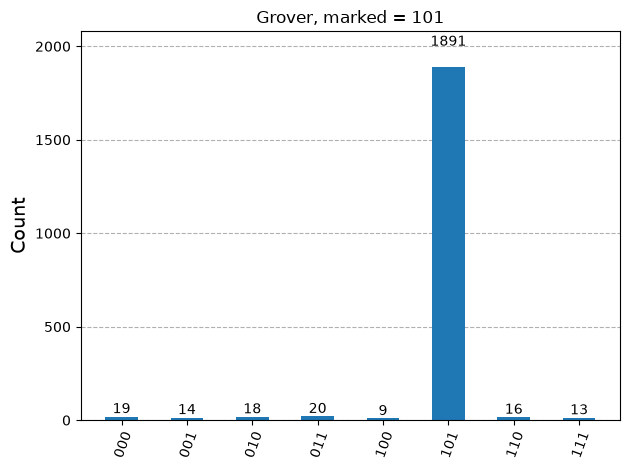

In [23]:
g.run(shots=2000).plot(title="Grover, marked = 101")

In [24]:
qp.grover(["0110", "1001"]).run().top(3)

[('1001', 4742), ('0110', 4697), ('1100', 51)]

## 9. Quantum Phase Estimation

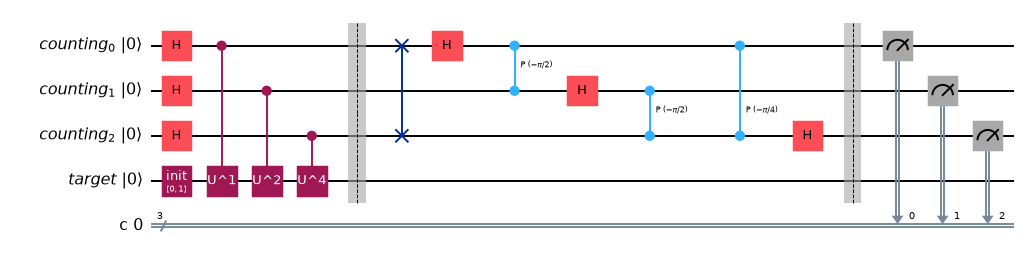

In [25]:
U = qp.P(2 * qp.pi * 0.375)          # e^{2πi·0.375} on |1>
qpe = qp.phase_estimation(U, n_counting=3, eigenstate="1")
qpe.draw(scale=0.7)

In [26]:
counts = qpe.run()
print(counts, " -> phase =", qp.estimated_phase(counts))

Counts({'011': 10000}, shots=10000)  -> phase = 0.375


In [27]:
# The QPE.ipynb example: eigenvalues of a 4x4 Hermitian matrix A
import numpy as np
A = np.array([[15, 9, 5, -3], [9, 15, 3, -5], [5, 3, 15, -9], [-3, -5, -9, 15]])
w, vecs = qp.eig(A)
print("eigenvalues:", w)
n = 5
ev = 4
t = -2 * qp.pi / ev / 2**n
U = qp.evolution_operator(A, t)       # e^{-iAt}
psi_0 = qp.ket([-0.5, 0.5, 0.5, 0.5])  # eigenvector for eigenvalue 4
counts = qp.phase_estimation(U, n_counting=n, eigenstate=psi_0).run()
phase = qp.estimated_phase(counts)
print("phase =", phase, " -> eigenvalue =", phase * 2 * qp.pi / (-t))   # expected 4

eigenvalues: [ 4.  8. 16. 32.]
phase = 0.03125  -> eigenvalue = 4.0


## 10. Trotterization (TP 8)

In [28]:
H = qp.hamiltonian({"ZZ": 1, "XI": -0.1})
for order in [1, 2, 4]:
    c = qp.trotter_circuit(H, time=20, steps=10, order=order)
    f = qp.fidelity(c.state(), qp.evolve(H, "00", 20))
    s = c.stats(show=False)
    print(f"order {order}: depth {s['depth']:>4}, gates {s['gates']:>4}, fidelity {f:.6f}")

order 1: depth   40, gates   50, fidelity 0.935112

order 2: depth   70, gates   80, fidelity 0.990052
order 4: depth  350, gates  360, fidelity 0.999854


## 11. Ising chain dynamics (TP 9)

final fidelity vs exact: 0.40365803000634154


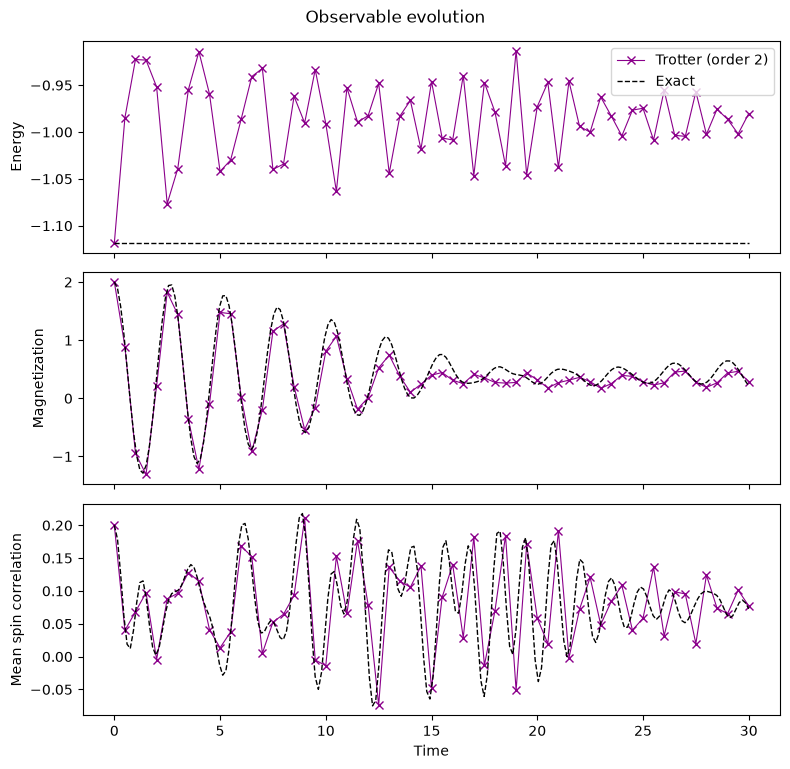

In [29]:
L = 6
H = qp.ising_chain(L, J=0.2, h=1.2, alpha=qp.pi / 8)
res = qp.time_evolution(
    H, "001100", time=30, steps=60, order=2,
    observables={"Energy": H,
                 "Magnetization": qp.magnetization(L),
                 "Mean spin correlation": qp.zz_correlation(L)},
)
print("final fidelity vs exact:", res.fidelity())
res.plot(exact=True);

## Cheatsheet

In [30]:
qp.cheatsheet("running")


== RUNNING ===============================================================
  QumPy                   Qiskit / numpy
  c.state()               Aer.get_backend('statevector_simulator').run(qc).result().get_statevector()
  c.unitary()             qi.Operator.from_circuit(qc)
  c.probabilities()       sv.probabilities_dict()
  c.run()                 Aer.get_backend('qasm_simulator').run(qc, shots=...).result().get_counts()
  c.run(backend='noisy')  FakeManilaV2().run(transpile(qc, backend), shots=...)
  counts.plot()           plot_histogram(counts)
  counts.most_likely()    max(counts, key=counts.get)
